Importing and loading 

In [13]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

# load the data split (test data)
_, X_test, _, y_test = joblib.load("../datasets/train_test_split.pkl")

# Loading the models ive saved
logreg = joblib.load("../models/logreg_model.pkl")
rf = joblib.load("../models/rf_model.pkl")

# making numeric binary values
y_test_num = y_test.map({"no": 0, "yes": 1})

print("Both models and test dataset loaded successfully!")

Both models and test dataset loaded successfully!


Performance comparison table

In [14]:
# show predictions for Logistic Regression
y_pred_lr = logreg.predict(X_test)
y_proba_lr = logreg.predict_proba(X_test)[:, 1]
y_pred_num_lr = pd.Series(y_pred_lr).map({"no": 0, "yes": 1})

# show preditions for Random Forest 
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]
y_pred_num_rf = pd.Series(y_pred_rf).map({"no": 0, "yes": 1})

# Comparing the data
comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy", 
        "Precision('yes')", 
        "Recall ('yes')",
         "F1Score ('yes')",
         "ROC AUC Score"
    ],
    "Logistic Regression": [
        accuracy_score(y_test_num, y_pred_num_lr),
        precision_score(y_test_num, y_pred_num_lr, pos_label=1),
        recall_score(y_test_num, y_pred_num_lr, pos_label=1),
        f1_score(y_test_num, y_pred_num_lr, pos_label=1),
        roc_auc_score(y_test_num, y_proba_lr)
    ],
    "Random Forest": [
        accuracy_score(y_test_num, y_pred_num_rf),
        precision_score(y_test_num, y_pred_num_rf, pos_label=1),
        recall_score(y_test_num, y_pred_num_rf, pos_label=1),
        f1_score(y_test_num, y_pred_num_rf, pos_label=1),
        roc_auc_score(y_test_num, y_proba_rf)
    ]

})

print("==Side by side Model comparison==")
display(comparison_df)



==Side by side Model comparison==


,Metric,Logistic Regression,Random Forest
0,Accuracy,0.830257,0.870204
1,Precision('yes'),0.359113,0.444444
2,Recall ('yes'),0.645474,0.607759
3,F1Score ('yes'),0.461479,0.513427
4,ROC AUC Score,0.800231,0.809074


ROC Curve Plot to compare

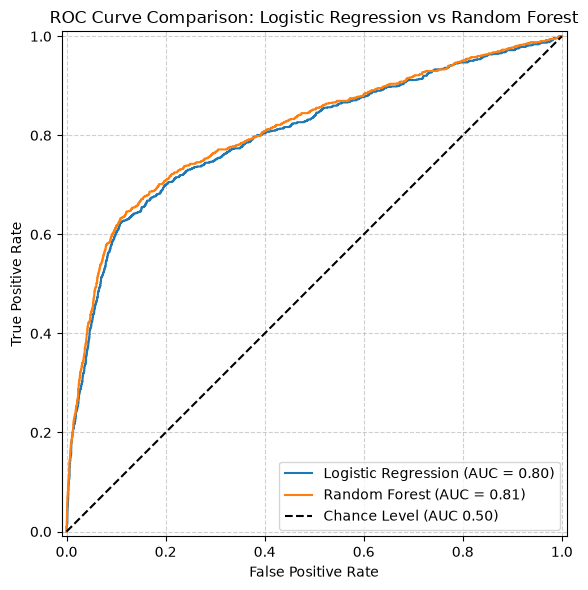

In [15]:
# have a combined ROC Curve chart
fig, ax =plt.subplots(figsize=(8,6))

RocCurveDisplay.from_predictions(
    y_test_num,
    y_proba_lr,
    name= "Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test_num,
    y_proba_rf,
    name="Random Forest",
    ax=ax
)

ax.plot([0,1], [0, 1], "k--", label="Chance Level (AUC 0.50)")
ax.set_title("ROC Curve Comparison: Logistic Regression vs Random Forest")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

# save the visual
plt.savefig("../scripts/visualisation/roc_curve_comparison.png", dpi =300)
plt.show()